   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 28.7 kB/s  0:00:34a 0:00:020:00:05m:04
OR  (unión):         0.8
AND (intersección):  0.4
NOT (complemento):   0.2
Propina sugerida: 19.85 %


/home/gina/Documentos/IA/Talleres/FFNN/venv/lib/python3.12/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


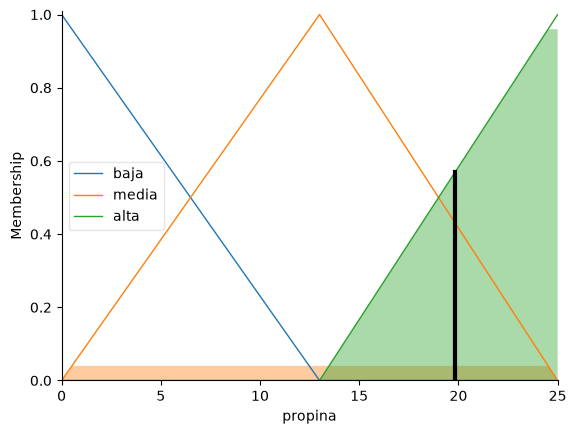


Comida | Servicio | Propina
  2    |    3     | 10.84 %
  5    |    5     | 12.67 %
  9    |    9     | 16.81 %
  2    |    9     | 13.06 %


In [3]:
!pip install scipy
!pip install networkx

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# ---------- EJERCICIO 1: Operaciones difusas ----------
alto = 0.8
pesado = 0.4

print("OR  (unión):        ", max(alto, pesado))
print("AND (intersección): ", min(alto, pesado))
print("NOT (complemento):  ", round(1 - alto, 2))

# ---------- EJERCICIO 2: Inferencia difusa (propina) ----------
# Variables lingüísticas
comida   = ctrl.Antecedent(np.arange(0, 11, 1), 'comida')
servicio = ctrl.Antecedent(np.arange(0, 11, 1), 'servicio')
propina  = ctrl.Consequent(np.arange(0, 26, 1), 'propina')

comida.automf(names=['mala', 'regular', 'buena'])
servicio.automf(names=['mala', 'regular', 'buena'])

propina['baja']  = fuzz.trimf(propina.universe, [0, 0, 13])
propina['media'] = fuzz.trimf(propina.universe, [0, 13, 25])
propina['alta']  = fuzz.trimf(propina.universe, [13, 25, 25])

# Reglas SI-ENTONCES
r1 = ctrl.Rule(servicio['mala'] | comida['mala'], propina['baja'])
r2 = ctrl.Rule(servicio['regular'], propina['media'])
r3 = ctrl.Rule(servicio['buena'] | comida['buena'], propina['alta'])

sistema = ctrl.ControlSystemSimulation(ctrl.ControlSystem([r1, r2, r3]))

# Caso principal (cámbienlo para experimentar)
sistema.input['comida'] = 6.5
sistema.input['servicio'] = 9.8
sistema.compute()
print("Propina sugerida:", round(sistema.output['propina'], 2), "%")

# Gráfica del resultado
propina.view(sim=sistema)
plt.savefig("propina.png")
plt.show()

# ---------- RETO: los 4 casos de la tabla ----------
print("\nComida | Servicio | Propina")
for c, s in [(2, 3), (5, 5), (9, 9), (2, 9)]:
    prueba = ctrl.ControlSystemSimulation(ctrl.ControlSystem([r1, r2, r3]))
    prueba.input['comida'] = c
    prueba.input['servicio'] = s
    prueba.compute()
    print(f"{c:^6} | {s:^8} | {prueba.output['propina']:.2f} %")